# Scary Stochastics, Week 4: Gibbs Sampling
## Notebook 1 of 3 — The Blob

### What is Gibbs sampling?

Say we have data and want to know the unknown parameters behind it — here, the average time survivors took to escape The Blob, and how much that time varies. Both unknowns depend on each other, which makes them hard to pin down at once. Gibbs sampling gets around this with one simple trick: **update one unknown at a time, holding the others fixed.**

1. Draw a new *mean*, given the current *spread*.
2. Draw a new *spread*, given the current *mean*.
3. Repeat thousands of times.

Each draw depends only on the one before it — so the sequence of draws is a **Markov chain**, the same idea as Week 1's pumpkin harvests, except the states are now parameter values instead of harvest categories. Run it long enough and the draws trace out the full range of parameter values that are plausible given the data.

Two practical notes: we start from a deliberately wrong guess, so the first stretch of draws (**burn-in**) gets thrown away; and consecutive draws are correlated, so 5,000 draws carry less information than 5,000 independent ones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln

# Monster palette (extends the series palette with one color per monster)
PALETTE = {
    "red":     "#C8102E",  # candy red - "true value" markers
    "orange":  "#E8741C",
    "rust":    "#B5451B",
    "purple":  "#3B2145",
    "mustard": "#D9A404",
    "magenta": "#B5338A",  # slime magenta - The Blob
    "teal":    "#2A7F7F",  # lagoon teal - Creature from the Black Lagoon
    "silver":  "#9AA5B4",  # moonlight silver - Werewolf
    "black":   "#1B1B1B",
    "cream":   "#FBF3E1",
}

N_ITER = 5000    # Gibbs iterations per monster
BURN_IN = 500    # early iterations we throw away

plt.rcParams.update({
    "figure.facecolor": PALETTE["cream"],
    "axes.facecolor": PALETTE["cream"],
    "axes.edgecolor": PALETTE["black"],
    "text.color": PALETTE["black"],
    "axes.labelcolor": PALETTE["black"],
    "xtick.color": PALETTE["black"],
    "ytick.color": PALETTE["black"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
})

def summarize(samples, truths):
    """Posterior summary (after burn-in) next to the true values used to simulate the data."""
    rows = []
    for name, s in samples.items():
        s = np.asarray(s)[BURN_IN:]
        rows.append([name, truths[name], s.mean(), np.percentile(s, 2.5), np.percentile(s, 97.5)])
    return pd.DataFrame(rows, columns=["Parameter", "True", "Post. mean", "2.5%", "97.5%"]).round(2)

### Simulate the data and run the sampler

The escape times below are simulated from known true values (mean 12 minutes, SD 3.5), so we can check at the end whether the sampler recovers them.

In [2]:
# ---- THE BLOB: how many minutes did survivors need to escape? ----
np.random.seed(1)
TRUE_MU, TRUE_SIGMA = 12.0, 3.5
blob_x = np.random.normal(TRUE_MU, TRUE_SIGMA, size=30)

n = len(blob_x)
m0, s0 = 10.0, 10.0   # weak prior on the mean
a0, b0 = 1.0, 1.0     # weak prior on the precision (1 / variance)

mu, tau = 20.0, 1 / 64   # deliberately far-off starting point (mean 20, SD 8)
blob_path = [(mu, 1 / np.sqrt(tau))]
blob_mu, blob_sigma = [], []
for i in range(N_ITER):
    # Step 1: draw the mean, holding the spread fixed
    prec = n * tau + 1 / s0 ** 2
    mu = np.random.normal((tau * blob_x.sum() + m0 / s0 ** 2) / prec, 1 / np.sqrt(prec))
    blob_path.append((mu, 1 / np.sqrt(tau)))
    # Step 2: draw the spread (as a precision), holding the mean fixed
    tau = np.random.gamma(a0 + n / 2, 1 / (b0 + 0.5 * ((blob_x - mu) ** 2).sum()))
    blob_path.append((mu, 1 / np.sqrt(tau)))
    blob_mu.append(mu)
    blob_sigma.append(1 / np.sqrt(tau))

blob_path = np.array(blob_path)
blob_mu, blob_sigma = np.array(blob_mu), np.array(blob_sigma)

summarize({"Mean escape time": blob_mu, "Spread (SD)": blob_sigma},
          {"Mean escape time": TRUE_MU, "Spread (SD)": TRUE_SIGMA})

,Parameter,True,Post. mean,2.5%,97.5%
0,Mean escape time,12.0,11.78,10.51,13.10
1,Spread (SD),3.5,3.58,2.82,4.65


### Visual 1 — The sampler's path

The black line shows the first six iterations: horizontal moves update the mean, vertical moves update the spread, and the chain quickly leaves its bad starting point (square) for the plausible region. The thin line shows the next stretch of small steps, and the magenta cloud is every post-burn-in draw.

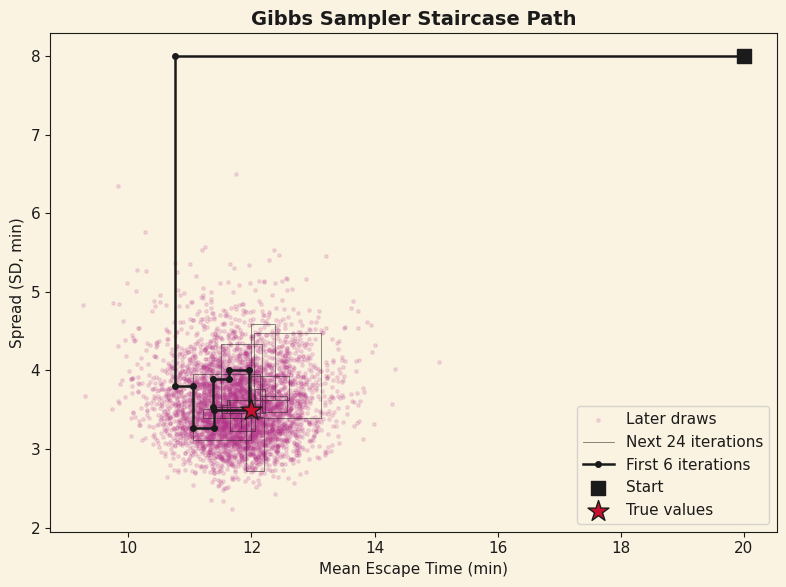

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(blob_mu[BURN_IN:], blob_sigma[BURN_IN:], s=6, color=PALETTE["magenta"],
           alpha=0.15, label="Later draws")
ax.plot(blob_path[12:61, 0], blob_path[12:61, 1], color=PALETTE["black"], linewidth=0.6,
        alpha=0.6, label="Next 24 iterations")
ax.plot(blob_path[:13, 0], blob_path[:13, 1], color=PALETTE["black"], linewidth=1.8,
        marker="o", markersize=4, label="First 6 iterations")
ax.scatter(*blob_path[0], color=PALETTE["black"], marker="s", s=90, zorder=4, label="Start")
ax.scatter(TRUE_MU, TRUE_SIGMA, color=PALETTE["red"], marker="*", s=250,
           edgecolors=PALETTE["black"], zorder=5, label="True values")
ax.set_xlabel("Mean Escape Time (min)")
ax.set_ylabel("Spread (SD, min)")
ax.set_title("Gibbs Sampler Staircase Path")
ax.legend()
plt.tight_layout()
plt.savefig("01_gibbs_staircase.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Visual 2 — How well does the fitted distribution match?

Each faint curve is a Normal distribution built from one posterior draw — the spread of the curves is the sampler's honest uncertainty, which is wide here because we only have 30 survivors.

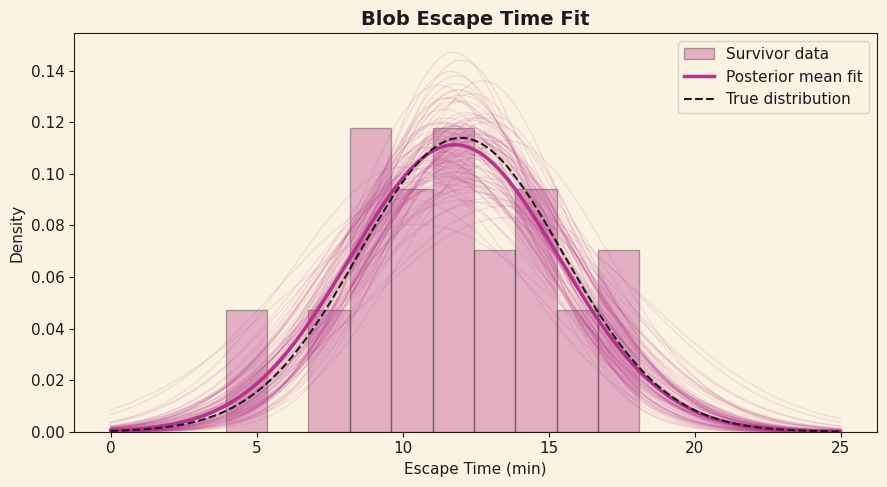

In [4]:
x_grid = np.linspace(0, 25, 300)
rng_idx = np.random.choice(np.arange(BURN_IN, N_ITER), size=100, replace=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(blob_x, bins=10, density=True, color=PALETTE["magenta"], alpha=0.35,
        edgecolor=PALETTE["black"], label="Survivor data")
for i in rng_idx:
    ax.plot(x_grid, stats.norm.pdf(x_grid, blob_mu[i], blob_sigma[i]),
            color=PALETTE["magenta"], alpha=0.12, linewidth=1)
ax.plot(x_grid, stats.norm.pdf(x_grid, blob_mu[BURN_IN:].mean(), blob_sigma[BURN_IN:].mean()),
        color=PALETTE["magenta"], linewidth=2.5, label="Posterior mean fit")
ax.plot(x_grid, stats.norm.pdf(x_grid, TRUE_MU, TRUE_SIGMA),
        color=PALETTE["black"], linestyle="--", linewidth=1.5, label="True distribution")
ax.set_xlabel("Escape Time (min)")
ax.set_ylabel("Density")
ax.set_title("Blob Escape Time Fit")
ax.legend()
plt.tight_layout()
plt.savefig("02_blob_fit.png", dpi=150, facecolor=PALETTE["cream"])
plt.show()

### Up next

Notebook 2 follows the Creature from the Black Lagoon, where one of the two steps isn't a textbook distribution and needs a different trick.